# From the HV grid to the house

An LV grid hangs on an MV ring, which is fed by an HV/MV substation on the 110 kV grid. pylovo's MV stage builds
the MV grids between the LV stations and the substations, and links each substation to its bus of the eTraGo
HV grid of eGon-data. This notebook follows one rural grid up the chain.

**Needs:** the `notebooks` extra (`uv sync --extra notebooks`). With a database in your `.env` the notebook reads the grids from it, otherwise from the example data that ship with pylovo (`data/examples`: three Bavarian postcode areas). With a database, the MV results come from it and the HV grid from `uv run pylovo-viewer fetch etrago`.

In [1]:
plz = 85307          # 80805 München (urban), 85256 Vierkirchen (semi-urban), 85307 Paunzhausen (rural)
version_id = None    # None: the version of your configuration, or of the example data
grid = None          # (kcid, bcid); None: the typical grid of the area

In [2]:
from pylovo.examples import TutorialData
from pylovo.plotting import style
from pylovo.plotting.voltage_levels import chain_table, plot_voltage_levels

style.apply_style(dpi=150)
data = TutorialData(plz, version_id)
kcid, bcid = grid or data.typical_grid
levels = data.voltage_levels(kcid, bcid)
data

TutorialData(plz=85307, version 1, from the example data: no database configured)

## 1 The chain

Each link of the connection with its key figures.

In [3]:
chain_table(levels["chain"])

,level,element,key figures
0,HV grid,110 kV bus of the eTraGo grid,bus 31651
1,HV/MV substation,Umspannwerk Kranzberg,"2 transformers, 25 MVA"
2,MV supply area,MV grid 254 at 20 kV,"135 stations, 3 rings, 188 km, 21.9 MW peak"
3,MV ring,"ring 2, position 32",1.012 p.u. at the station in the load case
4,MV/LV station,250 kVA,"tap 0, LV busbar 0.982 p.u."
5,LV grid,grid 1/6 of postcode area 85307,0.4 kV


## 2 Three maps, three voltage levels

Each map zooms into the box of the same colour and number in the map before.

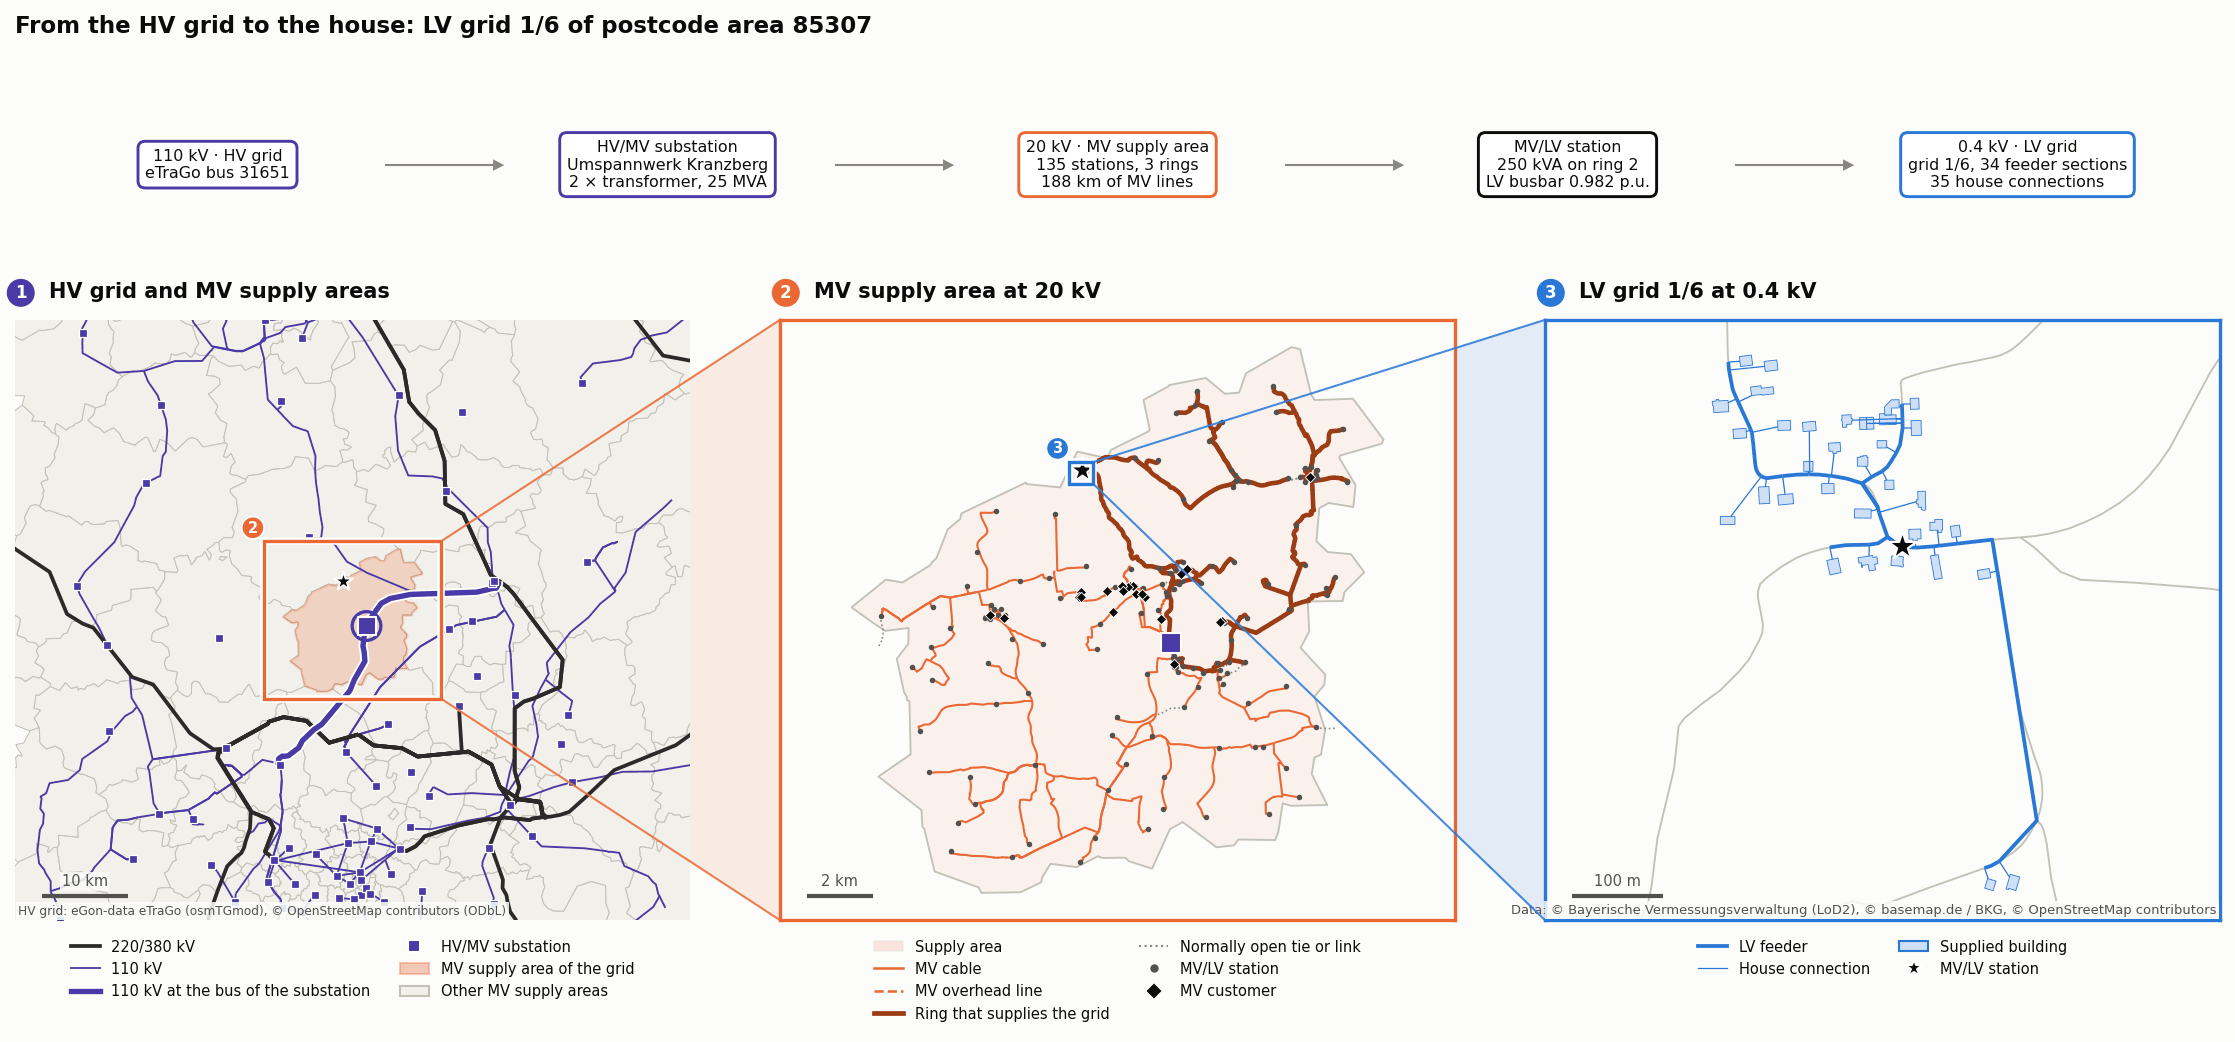

In [4]:
fig = plot_voltage_levels(levels["chain"], levels["hv"], levels["mv_context"], levels["mv_grid"], levels["lv"])

1. **HV grid.** The 110 kV lines at the eTraGo bus of the substation are drawn thick. Each MV supply area belongs to
   one HV/MV substation.
2. **MV grid.** The supply area at 20 kV with its rings. The dark ring supplies the station of the LV grid. Rings are
   operated open (dotted: normally open points), so each station has a second way back to the substation.
3. **LV grid.** The grid of the earlier notebooks, now with its place in the chain.

## 3 Where the layers come from

| Level | Source |
| --- | --- |
| 110–380 kV | eTraGo grid of eGon-data, built by osmTGmod from OpenStreetMap (2021) |
| HV/MV substations | OpenStreetMap, matched to the eTraGo buses (`egon_bus_id`) |
| MV grids | pylovo's MV stage (`pylovo-generate --mv` or `pylovo-mv`) |
| LV grids | pylovo |

## 4 When the chain is incomplete

The substations come from today's OpenStreetMap, the eTraGo grid from an older one, and a substation is matched to
an eTraGo bus only within 300 m. In the Bavaria run, 63 of 576 HV/MV substations have no eTraGo bus. One of them
supplies the semi-urban example area: no 110 kV line to it is mapped in OpenStreetMap, so eTraGo cannot connect it.
Set `plz = 85256` in the parameter cell to see it: the figure draws such a substation hollow and says so, and the
chain above the maps shows the missing link dashed. The MV and LV grids are complete either way.